In [149]:
import requests
import pandas as pd
from pathlib import Path

url = "https://raw.githubusercontent.com/prasertcbs/basic-dataset/master/Speed%20Dating%20Data.csv"
filename = Path(url).name.replace('%20', ' ')

print(f"Downloading {filename}...")

response = requests.get(url)
response.raise_for_status() # Raise an exception for HTTP errors

with open(filename, 'wb') as f:
    f.write(response.content)

print(f"Successfully downloaded {filename}")

Successfully downloaded Speed Dating Data.csv


In [150]:
df = pd.read_csv(filename, encoding="latin-1")
df.head()

,iid,id,gender,idg,condtn,wave,round,position,positin1,order,...,attr3_3,sinc3_3,intel3_3,fun3_3,amb3_3,attr5_3,sinc5_3,intel5_3,fun5_3,amb5_3
0,1,1.0,0,1,1,1,10,7,NaN,4,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
1,1,1.0,0,1,1,1,10,7,NaN,3,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
2,1,1.0,0,1,1,1,10,7,NaN,10,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
3,1,1.0,0,1,1,1,10,7,NaN,5,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN
4,1,1.0,0,1,1,1,10,7,NaN,7,...,5.0,7.0,7.0,7.0,7.0,NaN,NaN,NaN,NaN,NaN


In [151]:
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)
RANDOM_STATE = 42

In [152]:
URL = ("https://raw.githubusercontent.com/prasertcbs/basic-dataset/"
"master/Speed%20Dating%20Data.csv")
df = pd.read_csv(URL, encoding="latin-1")
print(f"Formato original: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Matches: {df['match'].sum()} ({df['match'].mean():.2%})")

Formato original: 8378 linhas x 195 colunas
Matches: 1380 (16.47%)


In [153]:
# 3.1 Remover variáveis que causam vazamento de dados
VAZAMENTO = ["dec", "dec_o", "you_call", "them_cal",
"date_3", "numdat_3", "num_in_3", "match_es"]

# 3.2 Escolher as variáveis explicativas
NOTAS_DADAS = ["attr", "sinc", "intel", "fun", "amb", "shar", "like", "prob"]
NOTAS_RECEBIDAS = ["attr_o", "sinc_o", "intel_o", "fun_o",
"amb_o", "shar_o", "like_o", "prob_o"]
NOTAS_AUTORAIS = ["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1",
                  "attr4_1", "sinc4_1", "intel4_1", "fun4_1", "amb4_1", "shar4_1",
                  "attr2_1", "sinc2_1", "intel2_1", "fun2_1", "amb2_1", "shar2_1",
                  "attr3_1", "sinc3_1", "intel3_1", "fun3_1", "amb3_1",
                  "attr5_1", "sinc5_1", "intel5_1", "fun5_1", "amb5_1",
                  "sports", "tvsports", "exercise", "dining", "museums", "art",
                  "hiking", "gaming", "clubbing", "reading", "tv", "theater",
                  "movies", "concerts", "music", "shopping", "yoga"]
CONTEXTO = ["int_corr", "samerace", "age", "age_o", "gender",
"order", "round", "imprace", "imprelig", "met", "met_o"]

CATEGORICAS = ["goal", "date", "go_out", "race", "race_o"]
NUMERICAS = NOTAS_DADAS + NOTAS_RECEBIDAS + CONTEXTO + NOTAS_AUTORAIS
FEATURES = NUMERICAS + CATEGORICAS
ALVO = "match"
dados = df[FEATURES + [ALVO]].copy()
# 3.3 Descartar linhas sem o resultado
dados = dados.dropna(subset=[ALVO])
# 3.4 Corrigir escalas quebradas: algumas ondas usaram escala 1-100 ao invés de 1-10
for col in NOTAS_DADAS + NOTAS_RECEBIDAS + NOTAS_AUTORAIS:
   # Caso o valor seja maior que 10 e menor que 96, divide por 10 arredondando para baixo.
   # Se for 96 ou maior, o valor deve ser 10.
   # Valores menores ou iguais a 10 não são alterados.
   dados[col] = dados[col].apply(lambda x: int(x // 10) if x > 10 and x < 96 else (10.0 if x >= 96 else x))

X = dados[FEATURES]
y = dados[ALVO].astype(int)

In [154]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

In [155]:
pre = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("padronizar", StandardScaler())
    ]), NUMERICAS),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("dummy", OneHotEncoder(handle_unknown="ignore", drop="first"))
    ]), CATEGORICAS),
])
modelo = Pipeline([
    ("pre", pre),
    ("logit", LogisticRegression(max_iter=2000, C=1.0,
                                random_state=RANDOM_STATE))
])
modelo.fit(X_treino, y_treino)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('padronizar',
                                                                   StandardScaler())]),
                                                  ['attr', 'sinc', 'intel',
                                                   'fun', 'amb', 'shar', 'like',
                                                   'prob', 'attr_o', 'sinc_o',
                                                   'intel_o', 'fun_o', 'amb_o',
                                                   'shar_o', 'like_o', 'prob_o',
                                                   'int_corr', 'samerace',
                                                   'age', 'age_o', 'gender',
                                                   'order', 'round', 'imprace',
                                                   'imprelig', 'met', 'met_o',
                                                   'attr1_1', 'sinc1_1',
                                                   'intel1_1', ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('dummy',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['goal', 'date', 'go_out',
                                                   'race', 'race_o'])])),
                ('logit', LogisticRegression(max_iter=2000, random_state=42))])

In [156]:
def avaliar(nome, mod, X_te, y_te):
  pred = mod.predict(X_te)
  prob = mod.predict_proba(X_te)[:, 1]
  print(f"Acurácia : {accuracy_score(y_te, pred):.4f}")
  print(f"Precisão : {precision_score(y_te, pred):.4f}")
  print(f"Recall : {recall_score(y_te, pred):.4f}")
  print(f"F1 : {f1_score(y_te, pred):.4f}")
  print(f"ROC AUC : {roc_auc_score(y_te, prob):.4f}")
  print(confusion_matrix(y_te, pred))
avaliar("Modelo padrão", modelo, X_teste, y_teste)

Acurácia : 0.8516
Precisão : 0.5928
Recall : 0.3164
F1 : 0.4126
ROC AUC : 0.8504
[[2010   90]
 [ 283  131]]


In [157]:
modelo_bal = Pipeline([
("pre", pre),
("logit", LogisticRegression(max_iter=2000,
class_weight="balanced",
random_state=RANDOM_STATE))
])
modelo_bal.fit(X_treino, y_treino)

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('padronizar',
                                                                   StandardScaler())]),
                                                  ['attr', 'sinc', 'intel',
                                                   'fun', 'amb', 'shar', 'like',
                                                   'prob', 'attr_o', 'sinc_o',
                                                   'intel_o', 'fun_o', 'amb_o',
                                                   'shar_o', 'like_o', 'prob_o',
                                                   'int_corr', 'samerace',
                                                   'age', 'age_o', 'gender',
                                                   'order', 'round', 'imprace',
                                                   'imprelig', 'met', 'met_o',
                                                   'attr1_1', 'sinc1_1',
                                                   'intel1_1', ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('dummy',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['goal', 'date', 'go_out',
                                                   'race', 'race_o'])])),
                ('logit',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [158]:
def avaliar(nome, mod, X_te, y_te):
  pred = mod.predict(X_te)
  prob = mod.predict_proba(X_te)[:, 1]
  print(f"Acurácia : {accuracy_score(y_te, pred):.4f}")
  print(f"Precisão : {precision_score(y_te, pred):.4f}")
  print(f"Recall : {recall_score(y_te, pred):.4f}")
  print(f"F1 : {f1_score(y_te, pred):.4f}")
  print(f"ROC AUC : {roc_auc_score(y_te, prob):.4f}")
  print(confusion_matrix(y_te, pred))
avaliar("Modelo padrão", modelo_bal, X_teste, y_teste)

Acurácia : 0.7768
Precisão : 0.4071
Recall : 0.7778
F1 : 0.5344
ROC AUC : 0.8523
[[1631  469]
 [  92  322]]


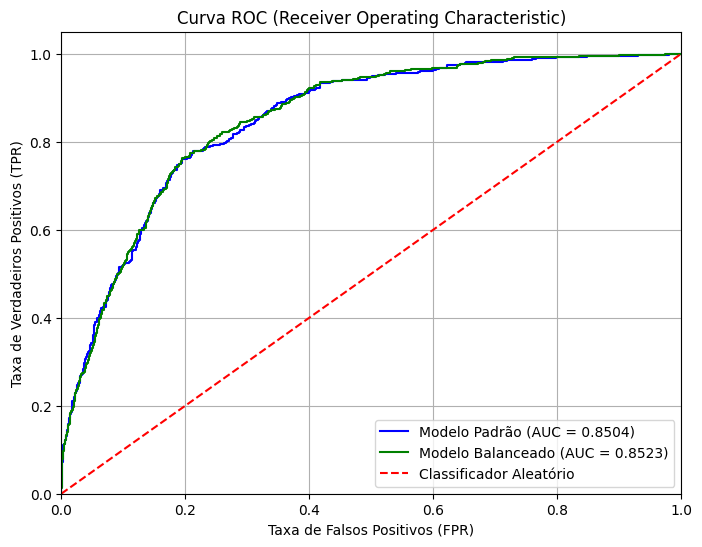

In [159]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Obter as probabilidades previstas para a classe positiva (1) para ambos os modelos
prob_padrao = modelo.predict_proba(X_teste)[:, 1]
prob_bal = modelo_bal.predict_proba(X_teste)[:, 1]

# Calcular as taxas de falsos positivos (FPR) e verdadeiros positivos (TPR)
fpr_padrao, tpr_padrao, _ = roc_curve(y_teste, prob_padrao)
fpr_bal, tpr_bal, _ = roc_curve(y_teste, prob_bal)

# Calcular a área sob a curva (AUC)
auc_padrao = auc(fpr_padrao, tpr_padrao)
auc_bal = auc(fpr_bal, tpr_bal)

# Plotar as curvas ROC utilizando Matplotlib
plt.figure(figsize=(8, 6))
plt.plot(fpr_padrao, tpr_padrao, color='blue', label=f'Modelo Padrão (AUC = {auc_padrao:.4f})')
plt.plot(fpr_bal, tpr_bal, color='green', label=f'Modelo Balanceado (AUC = {auc_bal:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')

# Configurações do gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC (Receiver Operating Characteristic)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# **TESTES COM STATS MODELS ABAIXO:**

In [160]:
import statsmodels.api as sm
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)

# 1. Obter os dados de treino pré-processados pelo ColumnTransformer anterior
X_treino_trans = pre.transform(X_treino)

# 2. Obter o nome das colunas geradas após o pré-processamento
nomes_num = NUMERICAS
nomes_cat = pre.named_transformers_['cat'].named_steps['dummy'].get_feature_names_out(CATEGORICAS)
todas_features = list(nomes_num) + list(nomes_cat)

# 3. Converter a matriz resultante em um DataFrame estruturado
X_treino_df = pd.DataFrame(X_treino_trans, columns=todas_features, index=X_treino.index)

# 4. Adicionar a constante (intercepto) exigida pelo statsmodels
X_treino_df = sm.add_constant(X_treino_df)

# 5. Ajustar o modelo Logit usando o statsmodels
modelo_sm = sm.Logit(y_treino, X_treino_df).fit(maxiter=2000)

# --- AVALIAÇÃO NO CONJUNTO DE TESTE ---

# A. Pré-processar as features de teste
X_teste_trans = pre.transform(X_teste)
X_teste_df = pd.DataFrame(X_teste_trans, columns=todas_features, index=X_teste.index)
X_teste_df = sm.add_constant(X_teste_df)

# B. Predições de probabilidade e classificação binária (threshold = 0.5)
prob_teste = modelo_sm.predict(X_teste_df)
pred_teste = (prob_teste >= 0.5).astype(int)

# C. Mostrar as métricas solicitadas
print(modelo_sm.summary())
print("\n" + "="*50)
print("MÉTRICAS DE AVALIAÇÃO (STATSMODELS - TESTE):")
print("="*50)
print(f"Acurácia : {accuracy_score(y_teste, pred_teste):.4f}")
print(f"Precisão : {precision_score(y_teste, pred_teste):.4f}")
print(f"Recall   : {recall_score(y_teste, pred_teste):.4f}")
print(f"F1       : {f1_score(y_teste, pred_teste):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_teste, prob_teste):.4f}")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_teste, pred_teste))

         Current function value: 0.307704
         Iterations: 2000


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                           Logit Regression Results                           
Dep. Variable:                  match   No. Observations:                 5864
Model:                          Logit   Df Residuals:                     5766
Method:                           MLE   Df Model:                           97
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.3123
Time:                        01:03:40   Log-Likelihood:                -1804.4
converged:                      False   LL-Null:                       -2623.8
Covariance Type:            nonrobust   LLR p-value:                2.023e-278
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.7456      0.453     -1.647      0.100      -1.633       0.142
attr           0.4883      0.065      7.473      0.000       0.360       0.616
sinc          -0.2157      0.069     -3.143      0.0

In [161]:
from sklearn.utils.class_weight import compute_sample_weight

# 1. Obter os dados de treino pré-processados
X_treino_trans = pre.transform(X_treino)
X_treino_df = pd.DataFrame(X_treino_trans, columns=todas_features, index=X_treino.index)
X_treino_df = sm.add_constant(X_treino_df)

# 2. Calcular os pesos balanceados para cada amostra com base em y_treino
pesos_treino = compute_sample_weight(class_weight="balanced", y=y_treino)

# 3. Ajustar o modelo GLM Binomial (equivalente à Regressão Logística) com pesos usando statsmodels
modelo_sm_bal = sm.GLM(
    y_treino,
    X_treino_df,
    family=sm.families.Binomial(),
    var_weights=pesos_treino
).fit(maxiter=2000)

# --- AVALIAÇÃO NO CONJUNTO DE TESTE ---

# A. Pré-processar as features de teste
X_teste_trans = pre.transform(X_teste)
X_teste_df = pd.DataFrame(X_teste_trans, columns=todas_features, index=X_teste.index)
X_teste_df = sm.add_constant(X_teste_df)

# B. Predições de probabilidade e classificação binária (threshold = 0.5)
prob_teste = modelo_sm_bal.predict(X_teste_df)
pred_teste = (prob_teste >= 0.5).astype(int)

# C. Mostrar os resultados e métricas solicitadas
print(modelo_sm_bal.summary())
print("\n" + "="*50)
print("MÉTRICAS DE AVALIAÇÃO (STATSMODELS BALANCEADO - TESTE):")
print("="*50)
print(f"Acurácia : {accuracy_score(y_teste, pred_teste):.4f}")
print(f"Precisão : {precision_score(y_teste, pred_teste):.4f}")
print(f"Recall   : {recall_score(y_teste, pred_teste):.4f}")
print(f"F1       : {f1_score(y_teste, pred_teste):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_teste, prob_teste):.4f}")
print("\nMatriz de Confusão:")
print(confusion_matrix(y_teste, pred_teste))

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  match   No. Observations:                 5864
Model:                            GLM   Df Residuals:                     5766
Model Family:                Binomial   Df Model:                           97
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2623.5
Date:                Sat, 07 Nov 2026   Deviance:                       5247.0
Time:                        01:03:44   Pearson chi2:                 6.73e+03
No. Iterations:                    22   Pseudo R-squ. (CS):             0.3883
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6551      0.398      1.645      0.1

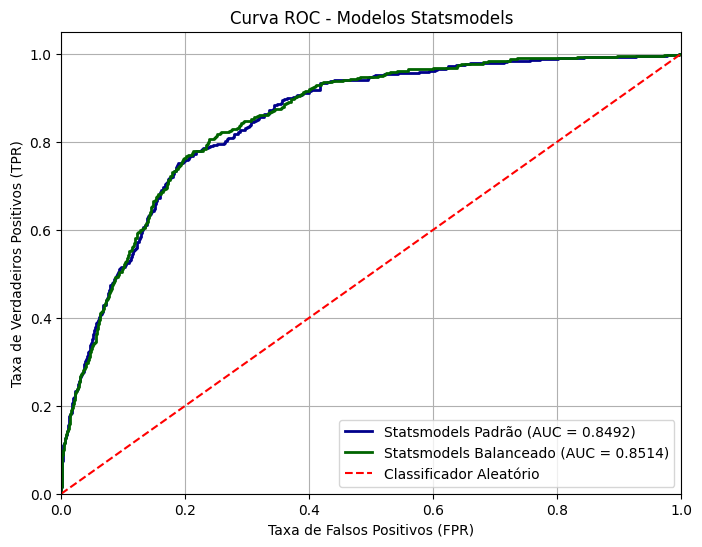

In [162]:
# 1. Obter as probabilidades previstas para o conjunto de teste com ambos os modelos do statsmodels
prob_sm = modelo_sm.predict(X_teste_df)
prob_sm_bal = modelo_sm_bal.predict(X_teste_df)

# 2. Calcular taxas de falsos positivos (FPR) e verdadeiros positivos (TPR)
fpr_sm, tpr_sm, _ = roc_curve(y_teste, prob_sm)
fpr_sm_bal, tpr_sm_bal, _ = roc_curve(y_teste, prob_sm_bal)

# 3. Calcular a área sob a curva (AUC)
auc_sm = auc(fpr_sm, tpr_sm)
auc_sm_bal = auc(fpr_sm_bal, tpr_sm_bal)

# 4. Plotar os resultados com o Matplotlib
plt.figure(figsize=(8, 6))
plt.plot(fpr_sm, tpr_sm, color='darkblue', lw=2, label=f'Statsmodels Padrão (AUC = {auc_sm:.4f})')
plt.plot(fpr_sm_bal, tpr_sm_bal, color='darkgreen', lw=2, label=f'Statsmodels Balanceado (AUC = {auc_sm_bal:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')

# Configurações do gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - Modelos Statsmodels')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# **GRÁFICOS ADICIONAIS ILUSTRATIVOS REFERENTES AO MODELO BALANCEADO DO SKLEARN (MODELO ESCOLHIDO)**

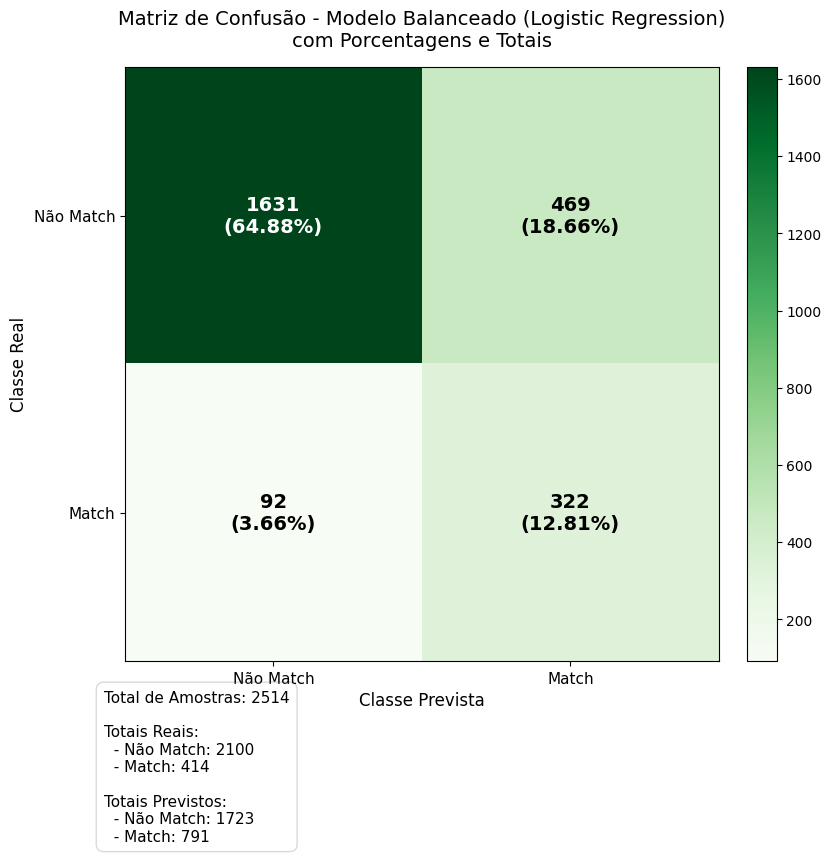

In [163]:
from sklearn.metrics import confusion_matrix

# 1. Calcular as previsões do modelo balanceado no conjunto de teste
y_pred_bal = modelo_bal.predict(X_teste)

# 2. Calcular a matriz de confusão
cm = confusion_matrix(y_teste, y_pred_bal)
total = np.sum(cm)

# 3. Plotar a matriz de confusão customizada para exibir valores, porcentagens e totais
fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(cm, interpolation='nearest', cmap='Greens')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Configurar rótulos dos eixos
classes = ['Não Match', 'Match']
tick_marks = np.arange(len(classes))
ax.set_xticks(tick_marks)
ax.set_xticklabels(classes, fontsize=11)
ax.set_yticks(tick_marks)
ax.set_yticklabels(classes, fontsize=11)

# Calcular totais marginais
totais_reais = cm.sum(axis=1)
totais_previstos = cm.sum(axis=0)

# Preencher cada quadrante com Valor, Porcentagem e indicação dos Totais
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        valor = cm[i, j]
        pct = (valor / total) * 100
        texto = f"{valor}\n({pct:.2f}%)"
        color = "white" if valor > thresh else "black"
        ax.text(j, i, texto, ha="center", va="center", color=color, fontsize=14, fontweight='bold')

# Títulos, rótulos e informações de suporte
plt.title('Matriz de Confusão - Modelo Balanceado (Logistic Regression)\ncom Porcentagens e Totais', fontsize=14, pad=15)
plt.xlabel('Classe Prevista', fontsize=12)
plt.ylabel('Classe Real', fontsize=12)

# Adicionar anotações de totais fora da matriz para clareza absoluta
info_totais = (
    f"Total de Amostras: {total}\n\n"
    f"Totais Reais:\n  - Não Match: {totais_reais[0]}\n  - Match: {totais_reais[1]}\n\n"
    f"Totais Previstos:\n  - Não Match: {totais_previstos[0]}\n  - Match: {totais_previstos[1]}"
)
plt.gcf().text(0.15, 0.02, info_totais, fontsize=11, bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.15))

plt.grid(False)
plt.subplots_adjust(bottom=0.22)  # Garante espaço para a legenda de totais
plt.show()

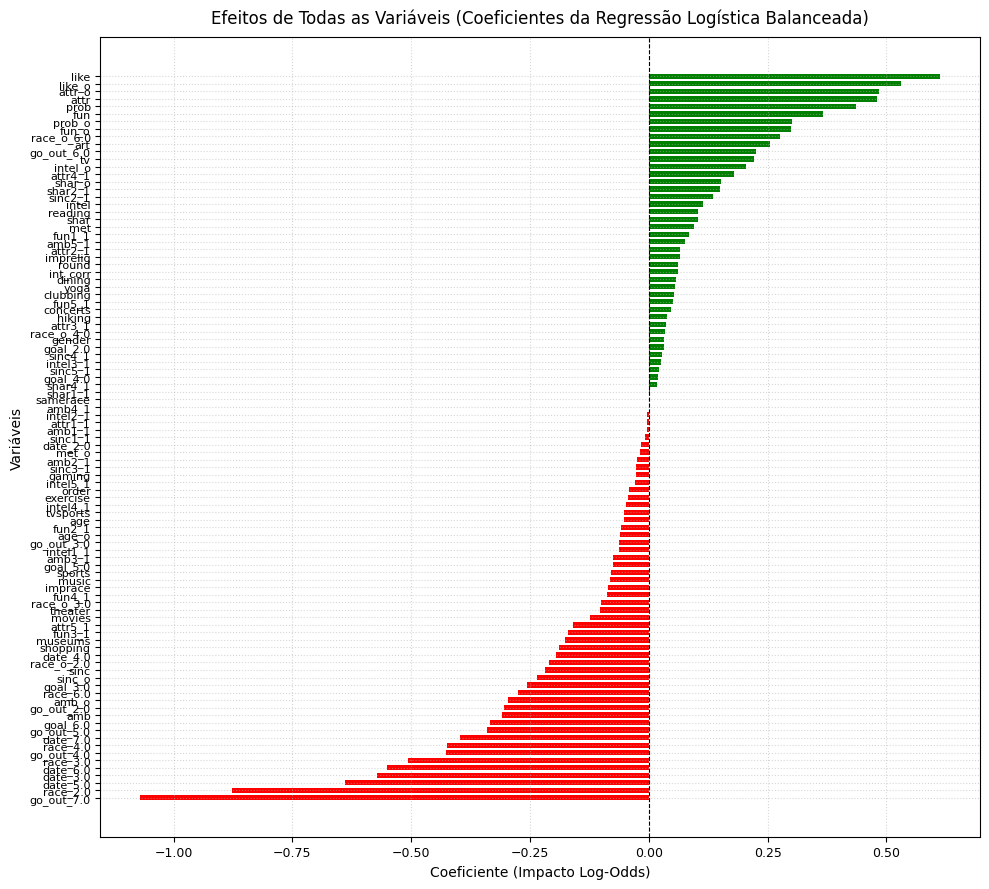

,Feature,Coeficiente,Abs_Coeficiente
0,go_out_7.0,-1.069973,1.069973
1,race_2.0,-0.877039,0.877039
2,date_5.0,-0.638506,0.638506
3,like,0.612840,0.612840
4,date_3.0,-0.572767,0.572767
5,date_6.0,-0.550808,0.550808
6,like_o,0.531204,0.531204
7,race_3.0,-0.506403,0.506403
8,attr_o,0.484630,0.484630
9,attr,0.479502,0.479502


In [164]:
# 1. Extrair os coeficientes e nomes de todas as features do pipeline balanceado
coeficientes = modelo_bal.named_steps['logit'].coef_[0]

# Obter nomes das colunas após o pré-processamento
nomes_num = NUMERICAS
nomes_cat = modelo_bal.named_steps['pre'].named_transformers_['cat'].named_steps['dummy'].get_feature_names_out(CATEGORICAS)
todas_features = list(nomes_num) + list(nomes_cat)

# 2. Criar um DataFrame para organizar todas as variáveis
df_importancia = pd.DataFrame({
    'Feature': todas_features,
    'Coeficiente': coeficientes
})

# Adicionar coluna com valores absolutos e ordenar as variáveis de forma decrescente para o gráfico
df_importancia['Abs_Coeficiente'] = df_importancia['Coeficiente'].abs()
df_importancia = df_importancia.sort_values(by='Coeficiente', ascending=True).reset_index(drop=True)

# 3. Plotar os efeitos de todas as variáveis disponíveis em tamanho compacto (sem rolagem)
plt.figure(figsize=(10, 9))
cores = ['green' if c > 0 else 'red' for c in df_importancia['Coeficiente']]
plt.barh(df_importancia['Feature'], df_importancia['Coeficiente'], color=cores, height=0.7)

plt.title('Efeitos de Todas as Variáveis (Coeficientes da Regressão Logística Balanceada)', fontsize=12, pad=10)
plt.xlabel('Coeficiente (Impacto Log-Odds)', fontsize=10)
plt.ylabel('Variáveis', fontsize=10)
plt.xticks(fontsize=9)
plt.yticks(fontsize=8)  # Ajuste da fonte para caber sem sobreposição
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

# Exibir a tabela completa ordenada por impacto absoluto para análise minuciosa
df_importancia_abs = df_importancia.copy()
df_importancia_abs['Abs_Coeficiente'] = df_importancia_abs['Coeficiente'].abs()

# Ajustar opções do pandas para exibir todas as 97 linhas sem omitir nenhuma
pd.set_option('display.max_rows', 100)
display(df_importancia_abs.sort_values(by='Abs_Coeficiente', ascending=False).reset_index(drop=True))

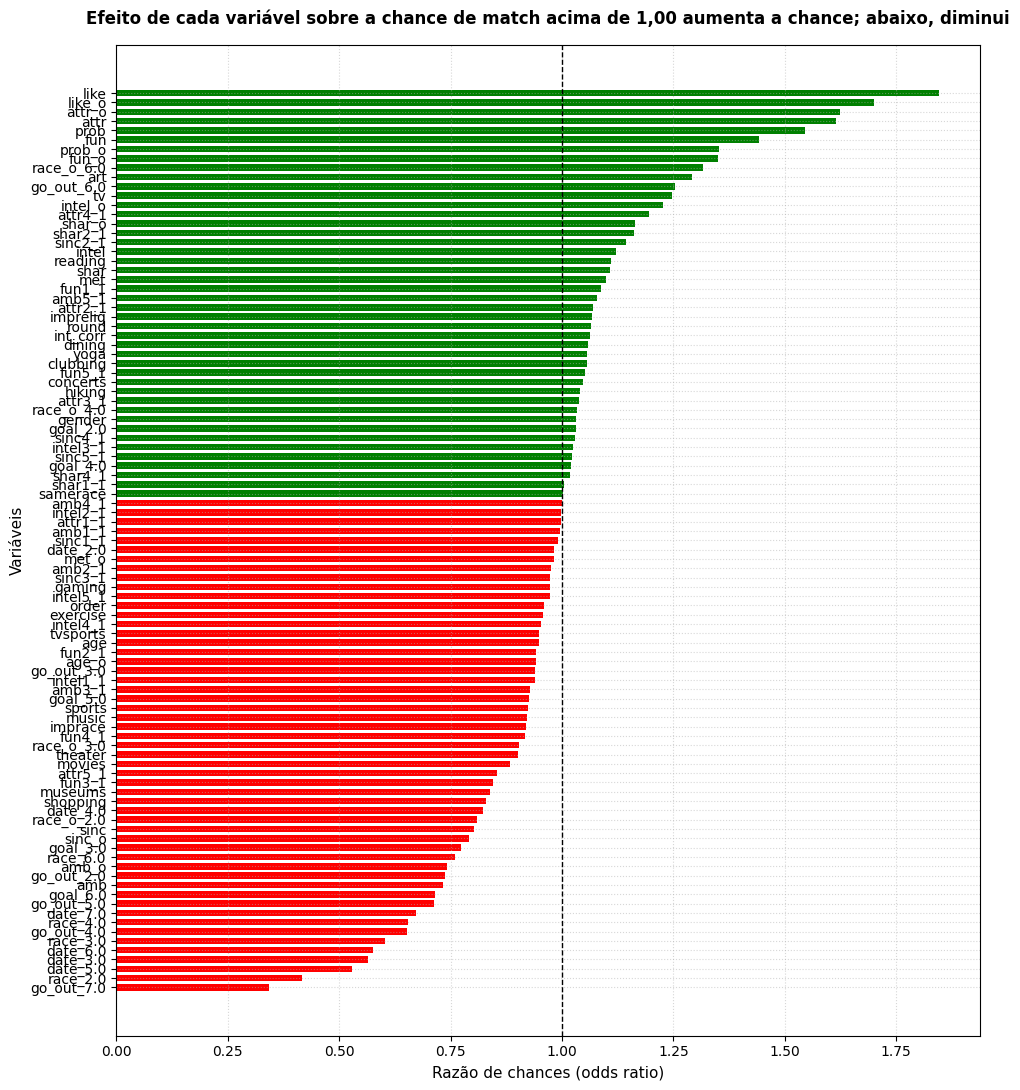

In [165]:
# 1. Extrair os coeficientes e nomes de todas as features do pipeline balanceado
coeficientes = modelo_bal.named_steps['logit'].coef_[0]
nomes_num = NUMERICAS
nomes_cat = modelo_bal.named_steps['pre'].named_transformers_['cat'].named_steps['dummy'].get_feature_names_out(CATEGORICAS)
todas_features = list(nomes_num) + list(nomes_cat)

# 2. Criar um DataFrame e calcular a Razão de Chances (Odds Ratio = exp(coeficiente))
df_or = pd.DataFrame({
    'Feature': todas_features,
    'Coeficiente': coeficientes
})
df_or['Odds Ratio'] = np.exp(df_or['Coeficiente'])

# Ordenar do menor para o maior Odds Ratio para o gráfico de barras horizontais
df_or = df_or.sort_values(by='Odds Ratio', ascending=True).reset_index(drop=True)

# 3. Plotar o gráfico
plt.figure(figsize=(10, 11))

# Cores para destacar acima de 1.0 (aumenta a chance) vs abaixo de 1.0 (diminui a chance)
cores = ['green' if r > 1.0 else 'red' for r in df_or['Odds Ratio']]

plt.barh(df_or['Feature'], df_or['Odds Ratio'], color=cores, height=0.7)

# Adicionar uma linha vertical no ponto neutro (Odds Ratio = 1.0)
plt.axvline(x=1.0, color='black', linestyle='--', linewidth=1.0)

# Ajustes de layout e eixos
titulo_solicitado = "Efeito de cada variável sobre a chance de match acima de 1,00 aumenta a chance; abaixo, diminui"
plt.title(titulo_solicitado, fontsize=12, pad=15, fontweight='bold')
plt.xlabel('Razão de chances (odds ratio)', fontsize=11)
plt.ylabel('Variáveis', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

# **SIMULAÇÃO - MATCH PERSONA**

In [166]:
from sklearn.preprocessing import StandardScaler

url_persona = 'https://raw.githubusercontent.com/RODRIGOAYUB/TCC_SPEED_DATING/main/arquivo_exemplo_persona.csv'
persona = pd.read_csv(url_persona)
if persona.shape[1] == 1:
    persona = pd.read_csv(url_persona, sep=';')

# 1. Limpar linhas nulas ou vazias
persona = persona.replace(r'^\s*$', np.nan, regex=True).dropna(how='all')

# 2. Identificar colunas preenchidas e válidas na persona
colunas_validas = [col for col in persona.columns if col in FEATURES and pd.notnull(persona[col].iloc[0]) and str(persona[col].iloc[0]).strip() != '']

# 3. Carregar base original e filtrar mulheres (gender=0)
df_original = pd.read_csv('/content/Speed Dating Data.csv', encoding='latin-1')

# Para evitar duplicados de perfil ao calcular similaridade, obter a primeira linha de cada mulher (gender=0)
mulheres = df_original[df_original['gender'] == 0].copy()
mulheres_agrupadas = mulheres.groupby('iid').first().reset_index()

# Garantir que as colunas da base tenham o mesmo tipo de escala e formato antes do cálculo
for col in colunas_validas:
    if col in NOTAS_DADAS + NOTAS_RECEBIDAS + NOTAS_AUTORAIS:
        mulheres_agrupadas[col] = pd.to_numeric(mulheres_agrupadas[col], errors='coerce')
        mulheres_agrupadas[col] = mulheres_agrupadas[col].apply(lambda x: int(x // 10) if pd.notnull(x) and x > 10 and x < 96 else (10.0 if pd.notnull(x) and x >= 96 else x))
    else:
        mulheres_agrupadas[col] = pd.to_numeric(mulheres_agrupadas[col], errors='coerce')

# Alinhar valores da persona com tipo float
valores_persona = {}
for col in colunas_validas:
    valores_persona[col] = float(persona[col].iloc[0])

# 4. Calcular similaridade baseada em distância Euclidiana Normalizada (Min-Max) para definir percentual de proximidade
dados_mulheres_sim = mulheres_agrupadas[['iid'] + colunas_validas].dropna().copy()

if not dados_mulheres_sim.empty:
    scaler = StandardScaler()
    valores_mulheres_scaled = scaler.fit_transform(dados_mulheres_sim[colunas_validas])
    vetor_persona_scaled = scaler.transform(pd.DataFrame([valores_persona])[colunas_validas])

    # Calcular distâncias euclidianas
    distancias = np.linalg.norm(valores_mulheres_scaled - vetor_persona_scaled, axis=1)
    max_dist = distancias.max() if distancias.max() > 0 else 1.0

    # Similaridade normalizada de 0% a 100%
    dados_mulheres_sim['similaridade'] = 1.0 - (distancias / max_dist)
    dados_mulheres_sim['distancia'] = distancias

    # Nova regra: Selecionar o percentil 75 de similaridade (que equivale ao percentil 25 de menor distância, ou seja, o top 25% mais similares)
    corte_similaridade = np.percentile(dados_mulheres_sim['similaridade'], 75)

    # Filtrar mulheres com similaridade acima do corte do percentil 75
    mulheres_filtradas_ids = dados_mulheres_sim[dados_mulheres_sim['similaridade'] >= corte_similaridade]['iid'].tolist()
    df_mulheres_filtradas = mulheres[mulheres['iid'].isin(mulheres_filtradas_ids)].copy()
else:
    mulheres_filtradas_ids = []
    df_mulheres_filtradas = mulheres.copy()
    corte_similaridade = 0.0

# 5. Definir estratégias de imputação baseadas nas mulheres similares
# Garantir tratamento de escalas na base de mulheres filtradas para as colunas numéricas de notas
for col in NOTAS_DADAS + NOTAS_RECEBIDAS + NOTAS_AUTORAIS:
    if col in df_mulheres_filtradas.columns:
        df_mulheres_filtradas[col] = pd.to_numeric(df_mulheres_filtradas[col], errors='coerce')
        df_mulheres_filtradas[col] = df_mulheres_filtradas[col].apply(lambda x: int(x // 10) if pd.notnull(x) and x > 10 and x < 96 else (10.0 if pd.notnull(x) and x >= 96 else x))

imputacoes_num = df_mulheres_filtradas[NUMERICAS].median()
imputacoes_cat = df_mulheres_filtradas[CATEGORICAS].mode().iloc[0] if not df_mulheres_filtradas[CATEGORICAS].mode().empty else X_treino[CATEGORICAS].mode().iloc[0]

# 6. Carregar potenciais parceiros masculinos (gender = 1)
homens = df_original[df_original['gender'] == 1].copy()
homens_agrupados = homens.groupby('iid').first().reset_index()

# 7. Construir o DataFrame de Simulação
simulacao_linhas = []

for _, homem in homens_agrupados.iterrows():
    linha_interacao = {}
    linha_interacao['gender'] = 0

    # Preencher características da persona (ou aplicar imputação baseada nas mulheres similares)
    for col in FEATURES:
        if col in persona.columns and pd.notnull(persona[col].iloc[0]) and str(persona[col].iloc[0]).strip() != '':
            linha_interacao[col] = persona[col].iloc[0]
        elif col == 'gender':
            linha_interacao['gender'] = 0
        else:
            if col in NUMERICAS:
                linha_interacao[col] = imputacoes_num[col] if pd.notnull(imputacoes_num.get(col)) else X_treino[col].median()
            elif col in CATEGORICAS:
                linha_interacao[col] = imputacoes_cat[col] if pd.notnull(imputacoes_cat.get(col)) else X_treino[col].mode().iloc[0]

    # Garantir que nenhum campo fique nulo
    for col in FEATURES:
        if col not in linha_interacao or pd.isnull(linha_interacao[col]):
            if col in NUMERICAS:
                linha_interacao[col] = X_treino[col].median()
            elif col in CATEGORICAS:
                linha_interacao[col] = X_treino[col].mode().iloc[0]

    # Mapear características do parceiro masculino
    linha_interacao['age_o'] = homem['age']
    linha_interacao['race_o'] = homem['race']

    # Atribuir notas recebidas
    linha_interacao['attr_o'] = homem['attr']
    linha_interacao['sinc_o'] = homem['sinc']
    linha_interacao['intel_o'] = homem['intel']
    linha_interacao['fun_o'] = homem['fun']
    linha_interacao['amb_o'] = homem['amb']
    linha_interacao['shar_o'] = homem['shar']
    linha_interacao['like_o'] = homem['like']
    linha_interacao['prob_o'] = homem['prob']

    # Atribuir notas dadas pela persona
    linha_interacao['attr'] = homem['attr_o']
    linha_interacao['sinc'] = homem['sinc_o']
    linha_interacao['intel'] = homem['intel_o']
    linha_interacao['fun'] = homem['fun_o']
    linha_interacao['amb'] = homem['amb_o']
    linha_interacao['shar'] = homem['shar_o']
    linha_interacao['like'] = homem['like_o']
    linha_interacao['prob'] = homem['prob_o']

    # Completar colunas de contexto
    linha_interacao['samerace'] = 1 if linha_interacao.get('race') == homem['race'] else 0
    linha_interacao['int_corr'] = homem['int_corr']
    linha_interacao['parceiro_iid'] = homem['iid']

    simulacao_linhas.append(linha_interacao)

df_simulacao = pd.DataFrame(simulacao_linhas)

# Reordenar colunas exatamente como no conjunto de treino
X_simulacao = df_simulacao[FEATURES].copy()

# Garantir coerência de tipos numéricos antes de aplicar escala
for col in NOTAS_DADAS + NOTAS_RECEBIDAS + NOTAS_AUTORAIS:
    if col in X_simulacao.columns:
        X_simulacao[col] = pd.to_numeric(X_simulacao[col], errors='coerce')
        X_simulacao[col] = X_simulacao[col].apply(lambda x: int(x // 10) if pd.notnull(x) and x > 10 and x < 96 else (10.0 if pd.notnull(x) and x >= 96 else x))

# Tratar eventuais nulos gerados na conversão
for col in NUMERICAS:
    if col in X_simulacao.columns:
        X_simulacao[col] = X_simulacao[col].fillna(X_treino[col].median())
for col in CATEGORICAS:
    if col in X_simulacao.columns:
        X_simulacao[col] = X_simulacao[col].fillna(X_treino[col].mode().iloc[0])

# 8. Realizar a predição utilizando o modelo balanceado
preds = modelo_bal.predict(X_simulacao)
probs = modelo_bal.predict_proba(X_simulacao)[:, 1]

# 9. Filtrar e exibir os matches sugeridos
df_simulacao['match_predito'] = preds
df_simulacao['probabilidade'] = probs

matches_sugeridos = df_simulacao[df_simulacao['match_predito'] == 1].sort_values(by='probabilidade', ascending=False)

print(f"Corte de similaridade (Percentil 75): {corte_similaridade:.2%}")
print(f"Total de mulheres com similaridade >= Corte: {len(mulheres_filtradas_ids)}")
print(f"Total de homens avaliados: {len(df_simulacao)}")
print(f"Total de matches sugeridos pelo modelo: {len(matches_sugeridos)}\n")
print("IDs dos parceiros sugeridos (iid) e probabilidade de match:")
print(matches_sugeridos[['parceiro_iid', 'probabilidade']].to_string(index=False))

Corte de similaridade (Percentil 75): 32.50%
Total de mulheres com similaridade >= Corte: 39
Total de homens avaliados: 277
Total de matches sugeridos pelo modelo: 106

IDs dos parceiros sugeridos (iid) e probabilidade de match:
 parceiro_iid  probabilidade
          127       0.997053
          128       0.989259
          169       0.988031
          107       0.987377
          122       0.984327
           13       0.984091
          339       0.983856
          168       0.983284
          366       0.978028
          333       0.975760
          337       0.975250
          161       0.957778
          125       0.955933
          129       0.955899
          460       0.954932
          334       0.936043
          373       0.933775
          170       0.928638
          137       0.926559
          332       0.919186
          140       0.911422
          173       0.910906
           19       0.901362
           97       0.895338
          308       0.887240
          249    

In [167]:
# 1. Filtrar os matches com probabilidade superior a 95%
top_matches = matches_sugeridos[matches_sugeridos['probabilidade'] > 0.95].copy()

# 2. Resgatar as características dos homens tratando nulos sistematicamente com base em X_treino
caracteristicas_top = []
for _, row in top_matches.iterrows():
    iid_parceiro = row['parceiro_iid']
    homem_original = homens_agrupados[homens_agrupados['iid'] == iid_parceiro].iloc[0].copy()

    # Dicionário para mapear os dados finais tratados do parceiro
    dados_parceiro_tratados = {}

    # Lista de colunas demográficas do parceiro presentes no modelo
    colunas_demograficas = ['age', 'race']

    for col in colunas_demograficas:
        val_original = homem_original[col]
        if pd.isnull(val_original):
            # Busca sistematicamente o valor de preenchimento (mediana ou moda) do X_treino
            if col == 'age':
                dados_parceiro_tratados[col] = X_treino['age'].median()
            elif col == 'race':
                dados_parceiro_tratados[col] = X_treino['race'].mode().iloc[0]
        else:
            dados_parceiro_tratados[col] = val_original

    info_detalhada = {
        'ID do Parceiro (iid)': int(iid_parceiro),
        'Probabilidade': f"{row['probabilidade']:.2%}",
        'Idade': dados_parceiro_tratados['age'],
        'Etnia (Código)': dados_parceiro_tratados['race'],
        'Atração Recebida (Pela Persona)': row['attr'],
        'Sinceridade Recebida': row['sinc'],
        'Inteligência Recebida': row['intel'],
        'Diversão Recebida': row['fun'],
        'Ambição Recebida': row['amb'],
        'Interesses Compartilhados Rec.': row['shar'],
        'Simpatia Geral (Like Persona)': row['like'],
        'Atração Dada (Pelo Parceiro)': row['attr_o'],
        'Sinceridade Dada': row['sinc_o'],
        'Inteligência Dada': row['intel_o'],
        'Diversão Dada': row['fun_o'],
        'Ambição Dada': row['amb_o'],
        'Interesses Compartilhados Dads.': row['shar_o'],
        'Simpatia Geral (Like Parceiro)': row['like_o'],
    }
    caracteristicas_top.append(info_detalhada)

df_top_detalhes = pd.DataFrame(caracteristicas_top)
display(df_top_detalhes)

,ID do Parceiro (iid),Probabilidade,Idade,Etnia (Código),Atração Recebida (Pela Persona),Sinceridade Recebida,Inteligência Recebida,Diversão Recebida,Ambição Recebida,Interesses Compartilhados Rec.,Simpatia Geral (Like Persona),Atração Dada (Pelo Parceiro),Sinceridade Dada,Inteligência Dada,Diversão Dada,Ambição Dada,Interesses Compartilhados Dads.,Simpatia Geral (Like Parceiro)
0,127,99.71%,22.0,2.0,10.0,6.0,7.0,8.0,8.0,8.0,8.0,10.0,7.0,9.0,10.0,8.0,10.0,10.0
1,128,98.93%,21.0,2.0,9.0,10.0,8.0,8.0,7.0,9.0,9.0,10.0,9.0,8.0,9.0,9.0,7.0,9.0
2,169,98.80%,28.0,2.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,8.0,8.0,9.0,8.0,7.0,8.0,8.0
3,107,98.74%,21.0,2.0,8.0,6.0,7.0,10.0,9.0,8.0,10.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0
4,122,98.43%,22.0,6.0,7.0,7.0,7.0,9.0,7.0,8.0,8.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0
5,13,98.41%,22.0,4.0,5.0,8.0,9.0,8.0,5.0,7.0,7.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0
6,339,98.39%,26.0,2.0,10.0,6.0,10.0,10.0,8.0,10.0,10.0,8.0,7.0,7.0,8.0,9.0,7.0,8.0
7,168,98.33%,23.0,4.0,6.0,9.0,9.0,10.0,9.0,10.0,10.0,8.0,8.0,7.0,7.0,7.0,8.0,8.0
8,366,97.80%,27.0,2.0,8.0,8.0,10.0,8.0,10.0,10.0,8.0,9.0,8.0,8.0,8.0,7.0,9.0,9.0
9,333,97.58%,23.0,2.0,10.0,7.0,10.0,10.0,6.0,8.0,10.0,6.0,6.0,7.0,7.0,5.0,4.0,7.0


In [168]:

# 1. Obter os valores da persona para as colunas válidas
perfil_persona = pd.DataFrame([valores_persona])

# 2. Obter a média das mesmas características para as mulheres do top 25% mais similares
# Usamos o df_mulheres_filtradas que contém as mulheres com similaridade acima do corte
perfil_similares_media = df_mulheres_filtradas[colunas_validas].mean().to_frame().T
perfil_similares_mediana = df_mulheres_filtradas[colunas_validas].median().to_frame().T

# 3. Criar uma tabela comparativa unindo as informações
comparativo_df = pd.DataFrame({
    'Característica': colunas_validas,
    'Valor na Persona': [valores_persona[col] for col in colunas_validas],
    'Média das Similares': [df_mulheres_filtradas[col].mean() for col in colunas_validas],
    'Mediana das Similares': [df_mulheres_filtradas[col].median() for col in colunas_validas]
})

# Adicionar coluna de diferença absoluta (Persona - Média)
comparativo_df['Diferença Absoluta (Persona - Média)'] = (comparativo_df['Valor na Persona'] - comparativo_df['Média das Similares']).abs()

# Ordenar por menor diferença para ver onde há maior alinhamento
comparativo_df = comparativo_df.sort_values(by='Diferença Absoluta (Persona - Média)').reset_index(drop=True)

print("=== COMPARAÇÃO: PERSONA vs. MULHERES MAIS SIMILARES (TOP 25%) ===")
display(comparativo_df)

=== COMPARAÇÃO: PERSONA vs. MULHERES MAIS SIMILARES (TOP 25%) ===


,Característica,Valor na Persona,Média das Similares,Mediana das Similares,Diferença Absoluta (Persona - Média)
0,gender,0.0,0.000000,0.0,0.000000
1,gaming,3.0,2.964451,3.0,0.035549
2,attr5_1,7.0,7.055641,7.0,0.055641
3,race,3.0,2.901082,2.0,0.098918
4,sinc3_1,8.0,8.105100,8.0,0.105100
5,date,5.0,5.112828,5.0,0.112828
6,amb4_1,7.0,6.876352,10.0,0.123648
7,amb5_1,8.0,7.811437,8.0,0.188563
8,goal,2.0,2.221020,2.0,0.221020
9,fun3_1,8.0,7.704791,8.0,0.295209


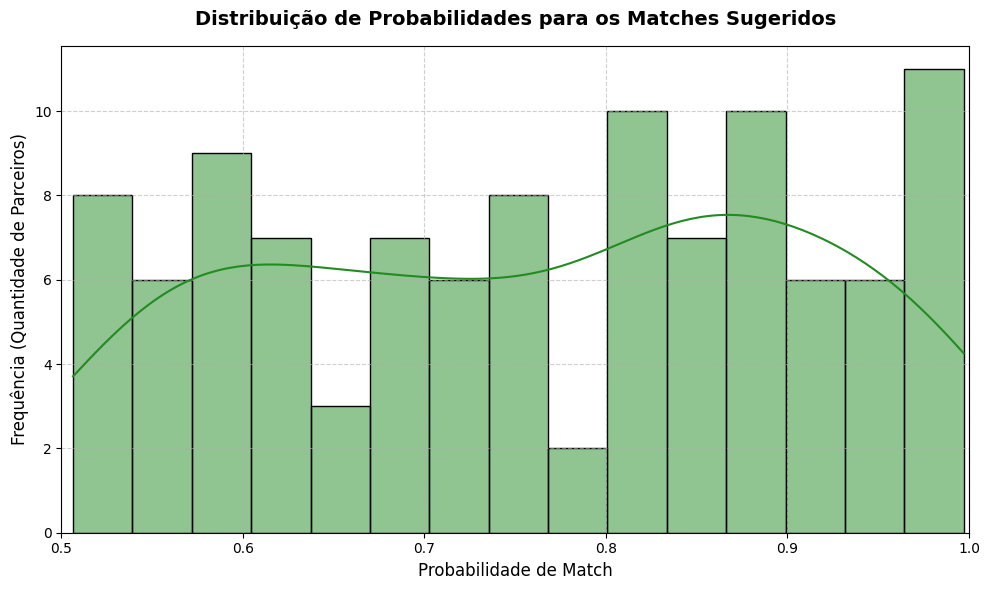

In [169]:
plt.figure(figsize=(10, 6))
sns.histplot(matches_sugeridos['probabilidade'], kde=True, color='forestgreen', bins=15, edgecolor='black')

plt.title('Distribuição de Probabilidades para os Matches Sugeridos', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Probabilidade de Match', fontsize=12)
plt.ylabel('Frequência (Quantidade de Parceiros)', fontsize=12)
plt.xlim([0.5, 1.0])
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()